# Motivace, způsob učení a výsledky v přírodních vědách

Autor: Ondřej Zetek

**Q1 (4ft-Miner):** Které kombinace motivace k přírodním vědám a studijních návyků
souvisejí s vyšší úrovní Science?

**Q2 (CF-Miner):** Jak se mění rozdělení výsledků Science podle času a způsobu učení
(domácí úkoly, učení navíc, plánování učení, vytrvalost)? Kde víc učení souvisí
s lepšími výsledky a kde ne?

Navazuje na `03_vojtech_rodinne_zazemi.ipynb` (stejný Parquet, ošetření chybějících kódů,
země GBR, vyšší Science = PV1SCIE nad 75. percentilem analytického vzorku) a na exploraci
v `04_ondrej_motivace_uceni_eda.ipynb`. Výstupy pro prezentaci se ukládají do `outputs/ondrej/`.

In [1]:
from pathlib import Path
import contextlib
import io
import json

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import pyarrow.parquet as pq
from cleverminer import cleverminer

PROJECT = Path.cwd()
if PROJECT.name == "notebooks":
    PROJECT = PROJECT.parent

DATA = PROJECT / "data/processed/student_full.parquet"
METADATA = PROJECT / "data/processed/student_full_metadata.json"
OUTPUT = PROJECT / "outputs/ondrej"
OUTPUT.mkdir(parents=True, exist_ok=True)

if not DATA.is_file() or not METADATA.is_file():
    raise FileNotFoundError("Najprv priprav plný Parquet podľa kroku 5 v README.")

metadata = json.loads(METADATA.read_text(encoding="utf-8"))
parquet = pq.ParquetFile(DATA)
if json.loads(parquet.schema_arrow.metadata[b"pisa_metadata"]) != metadata:
    raise ValueError("Parquet a metadata JSON nepatria k sebe. Použi oba súbory z rovnakého prevodu.")

by_name = {column["name"]: column for column in metadata["columns"]}
print(f"Záznamy: {parquet.metadata.num_rows:,}")
print(f"Premenné: {parquet.metadata.num_columns}")

Cleverminer version  1.2.8
Záznamy: 755,721
Premenné: 885


## Pomocné funkce pro export

Výpisy CleverMineru zachytáváme do textu, zobrazujeme v notebooku a ukládáme
jako TXT i PNG (PNG slouží jako „screenshot“ do prezentace).

In [2]:
def captured(function, *args, **kwargs):
    buffer = io.StringIO()
    with contextlib.redirect_stdout(buffer):
        function(*args, **kwargs)
    return buffer.getvalue()


def save_text(text, name, title=None):
    text = text.strip("\n")
    (OUTPUT / f"{name}.txt").write_text(text + "\n", encoding="utf-8")

    lines = text.splitlines()
    width = max(len(line) for line in lines)
    fig = plt.figure(figsize=(max(6, 0.072 * width), 0.6 + 0.19 * (len(lines) + (2 if title else 0))))
    content = (f"{title}\n\n" if title else "") + text
    fig.text(0.01, 0.98, content, family="monospace", fontsize=8.5, va="top")
    fig.savefig(OUTPUT / f"{name}.png", dpi=200, bbox_inches="tight", facecolor="white")
    plt.close(fig)
    print(text)


def quiet_cleverminer(**kwargs):
    with contextlib.redirect_stdout(io.StringIO()):
        return cleverminer(**kwargs)

## Načtení a chybějící hodnoty

Kódy chybějících hodnot převádíme na `NaN` podle metadat (stejně jako Vojtěch).

In [3]:
Q1_SOURCE = ["EFFSCIE", "ST094Q05NA", "PERSEV", "ST307Q10JA", "TARDYSD", "SKIPPING", "EXPECEDU"]
Q2_SOURCE = ["ST296Q04JA", "ST071Q01NA", "ST432Q02DA", "PERSEV"]
SCIENCE = [f"PV{i}SCIE" for i in range(1, 11)]

SOURCE = list(dict.fromkeys(Q1_SOURCE + Q2_SOURCE))
COLUMNS = ["CNT", "CNTSTUID", "W_FSTUWT"] + SOURCE + SCIENCE

df = pd.read_parquet(DATA, columns=COLUMNS, filters=[("CNT", "==", "GBR")])

for name in COLUMNS:
    for interval in by_name[name]["missing_ranges"]:
        df.loc[df[name].between(interval["lo"], interval["hi"]), name] = np.nan

pd.DataFrame({
    "popis": {name: by_name[name]["label"] for name in SOURCE},
    "chybejici_pct": df[SOURCE].isna().mean().mul(100).round(1),
})

,popis,chybejici_pct
EFFSCIE,Science self-efficacy (WLE),10.0
ST094Q05NA,How much do you disagree or agree with the sta...,9.3
PERSEV,Students' perseverance (WLE),14.9
ST307Q10JA,To what extent do you agree or disagree with t...,15.4
TARDYSD,Arriving late for school,6.1
SKIPPING,Skipping of classes or days of school,5.6
EXPECEDU,Highest expected educational level,18.4
ST296Q04JA,"In a typical school week, approximately how mu...",13.6
ST071Q01NA,"This school year, approximately how many hours...",20.8
ST432Q02DA,"For each way of learning, please indicate how ...",17.8


---
# Q1 – 4ft-Miner: motivace a návyky ⇒ vyšší Science

## Analytický vzorek

Studenti GBR s vyplněnými všemi proměnnými Q1 a všemi deseti PV.

In [4]:
q1 = df.loc[df[Q1_SOURCE + SCIENCE].notna().all(axis=1)].copy()

print("Studenti GBR:", len(df))
print("Analytický vzorek Q1:", len(q1))
print("Zachováno (%):", round(100 * len(q1) / len(df), 1))
print("Duplicitní identifikátory:", q1.duplicated(["CNT", "CNTSTUID"]).sum())

Studenti GBR: 15546
Analytický vzorek Q1: 11478
Zachováno (%): 73.8
Duplicitní identifikátory: 0


## Kategorizace

Hranice určujeme před hledáním pravidel.

- Indexy sebedůvěry (EFFSCIE) a vytrvalosti (PERSEV): nízká / střední / vysoká podle 25. a 75. percentilu
  analytického vzorku (relativní kategorie, ne úrovně OECD).
- Odpovědi na škálách: podle významu odpovědí; slučujeme jen málo obsazené krajní kategorie.
- Prefixy `1_`, `2_` … drží pořadí kategorií pro typ `seq` (sousední kategorie).

In [5]:
def terciles_by_quartiles(series):
    q25, q75 = series.quantile([0.25, 0.75])
    if q25 >= q75:
        raise ValueError(f"{series.name}: nelze vytvořit tři odlišné intervaly.")
    return pd.cut(series, [-np.inf, q25, q75, np.inf], labels=["nizka", "stredni", "vysoka"]), (q25, q75)


def ordered(series, mapping):
    labels = sorted(set(mapping.values()))
    return pd.Categorical(series.map(mapping), categories=labels, ordered=True)


q1_cat = pd.DataFrame(index=q1.index)
boundaries = []

for source, target in [("EFFSCIE", "sebeduvera"), ("PERSEV", "vytrvalost")]:
    q1_cat[target], (q25, q75) = terciles_by_quartiles(q1[source])
    boundaries.append({"promenna": source, "kategorie": target, "hranice_nizka_stredni": q25, "hranice_stredni_vysoka": q75})

q1_cat["zajem"] = ordered(q1["ST094Q05NA"], {1: "1_rozhodne_ne", 2: "2_ne", 3: "3_ano", 4: "4_rozhodne_ano"})
q1_cat["vzdava_se"] = ordered(q1["ST307Q10JA"], {1: "1_ne", 2: "1_ne", 3: "2_neutralne", 4: "3_ano", 5: "3_ano"})
q1_cat["pozde"] = ordered(q1["TARDYSD"], {0: "0_nikdy", 1: "1_obcas", 2: "2_casto"})
q1_cat["zaskolactvi"] = q1["SKIPPING"].map({0: "ne", 1: "ano"})
q1_cat["ocek_vzdelani"] = ordered(q1["EXPECEDU"], {
    1: "1_nejvyse_ISCED33", 2: "1_nejvyse_ISCED33", 3: "1_nejvyse_ISCED33",
    4: "2_ISCED34_az_5", 5: "2_ISCED34_az_5", 6: "2_ISCED34_az_5",
    7: "3_VS", 8: "3_VS", 9: "3_VS",
})

if q1_cat.isna().any().any():
    raise ValueError("Po kategorizaci vznikly chybějící hodnoty.")

boundaries = pd.DataFrame(boundaries)
boundaries.to_csv(OUTPUT / "q1_hranice_indexu.csv", index=False)
display(boundaries.round(3))

counts = pd.concat(
    {name: q1_cat[name].value_counts(sort=False) for name in q1_cat.columns},
    names=["atribut", "kategorie"],
).rename("pocet").to_frame()
counts["podil_pct"] = (100 * counts["pocet"] / len(q1_cat)).round(1)
counts.to_csv(OUTPUT / "q1_kategorie.csv")
counts

,promenna,kategorie,hranice_nizka_stredni,hranice_stredni_vysoka
0,EFFSCIE,sebeduvera,-0.340,0.832
1,PERSEV,vytrvalost,-0.624,0.380


pocet  podil_pct
atribut       kategorie                          
sebeduvera    nizka               2874       25.0
              stredni             5755       50.1
              vysoka              2849       24.8
vytrvalost    nizka               2915       25.4
              stredni             6296       54.9
              vysoka              2267       19.8
zajem         1_rozhodne_ne       1357       11.8
              2_ne                2722       23.7
              3_ano               5416       47.2
              4_rozhodne_ano      1983       17.3
vzdava_se     1_ne                5754       50.1
              2_neutralne         2996       26.1
              3_ano               2728       23.8
pozde         0_nikdy             6445       56.2
              1_obcas             3371       29.4
              2_casto             1662       14.5
zaskolactvi   ne                  7588       66.1
              ano                 3890       33.9
ocek_vzdelani 1_nejvyse_ISCED33   2085       18.2
              2_ISCED34_az_5      3472       30.2
              3_VS                5921       51.6

## Cílová proměnná

Vyšší Science = PV1SCIE nad 75. percentilem analytického vzorku (stejná definice jako u Vojtěcha),
výchozí podíl je tedy 25 %.

In [6]:
Q1_THRESHOLD = float(q1["PV1SCIE"].quantile(0.75))

q1_rules = q1_cat.copy()
q1_rules["science"] = pd.Categorical(
    np.where(q1["PV1SCIE"] > Q1_THRESHOLD, "vyssi", "ostatni"),
    categories=["vyssi", "ostatni"],
    ordered=True,
)
Q1_BASELINE = q1_rules["science"].eq("vyssi").mean()

print(f"Hranice Science: > {Q1_THRESHOLD:.2f}")
print(f"Výchozí podíl vyšší Science: {Q1_BASELINE:.2%}")

Hranice Science: > 587.37
Výchozí podíl vyšší Science: 25.00%


## Zadání 4ft-Mineru

- **Antecedent:** konjunkce 1–3 atributů. Uspořádané atributy jako `seq` (1–2 sousední kategorie,
  např. *sebedůvěra střední nebo vysoká*), záškoláctví jako `subset` (jedna kategorie).
- **Sukcedent:** `science(vyssi)` (typ `lcut` délky 1 = první kategorie).
- **Kvantifikátory:** Base ≥ 200 (aspoň 200 studentů splňuje antecedent i sukcedent)
  a confidence ≥ 0,55 – podíl vyšší Science ve skupině je aspoň 2,2× vyšší než výchozích 25 %.

In [7]:
Q1_ATTRIBUTES = ["sebeduvera", "zajem", "vytrvalost", "vzdava_se", "pozde", "ocek_vzdelani", "zaskolactvi"]
Q1_QUANTIFIERS = {"Base": 200, "conf": 0.55}

clm_q1 = quiet_cleverminer(
    df=q1_rules[Q1_ATTRIBUTES + ["science"]].copy(),
    proc="4ftMiner",
    quantifiers=Q1_QUANTIFIERS,
    ante={
        "attributes": [
            {"name": name, "type": "subset" if name == "zaskolactvi" else "seq", "minlen": 1,
             "maxlen": 1 if name == "zaskolactvi" else 2}
            for name in Q1_ATTRIBUTES
        ],
        "minlen": 1,
        "maxlen": 3,
        "type": "con",
    },
    succ={
        "attributes": [{"name": "science", "type": "lcut", "minlen": 1, "maxlen": 1}],
        "minlen": 1,
        "maxlen": 1,
        "type": "con",
    },
)

save_text(captured(clm_q1.print_summary), "q1_souhrn")
save_text(captured(clm_q1.print_rulelist), "q1_seznam_pravidel", title="Q1 – 4ft-Miner: motivace a návyky => vyšší Science (GBR)")

CleverMiner task processing summary:

Task type : 4ftMiner
Number of verifications : 1849
Number of rules : 28
Total time needed : 00h 00m 00s
Time of data preparation : 00h 00m 00s
Time of rule mining : 00h 00m 00s


List of rules:
RULEID BASE  CONF  AAD    Rule
     1   630 0.551 +1.202 sebeduvera(stredni vysoka) & zajem(4_rozhodne_ano) & vzdava_se(1_ne) => science(vyssi) | ---
     2   618 0.558 +1.231 sebeduvera(stredni vysoka) & zajem(4_rozhodne_ano) & pozde(0_nikdy) => science(vyssi) | ---
     3   706 0.554 +1.215 sebeduvera(stredni vysoka) & zajem(4_rozhodne_ano) & ocek_vzdelani(3_VS) => science(vyssi) | ---
     4   528 0.581 +1.326 sebeduvera(vysoka) & zajem(4_rozhodne_ano) => science(vyssi) | ---
     5   266 0.556 +1.226 sebeduvera(vysoka) & zajem(4_rozhodne_ano) & vytrvalost(nizka stredni) => science(vyssi) | ---
     6   204 0.570 +1.279 sebeduvera(vysoka) & zajem(4_rozhodne_ano) & vytrvalost(stredni) => science(vyssi) | ---
     7   466 0.591 +1.365 sebeduvera(vysoka) & zajem(4_rozhodne_ano) & vytrvalost(stredni vysoka) => science(vyssi) | ---
     8   262 0.609 +1.437 sebeduvera(vysoka) & zajem(4_rozhodne_ano) & vytrvalost(vysoka) => science(vyssi) | ---
     9   388 0.627 +1.507 seb

## Detail vybraných pravidel

1. **Jádro:** vysoká sebedůvěra & rozhodný zájem o přírodní vědy.
2. **Jádro + návyk:** totéž & student nikdy nechodí pozdě – ukazuje, o kolik se podíl zvýší
   po přidání studijního návyku.

In [8]:
def rule_id(clm, antecedent):
    matches = [rule["rule_id"] for rule in clm.result["rules"] if rule["cedents_str"]["ante"] == antecedent]
    if len(matches) != 1:
        raise ValueError(f"Pravidlo nenalezeno jednoznačně: {antecedent}")
    return matches[0]


Q1_SELECTED = {
    "jadro": "sebeduvera(vysoka) & zajem(4_rozhodne_ano)",
    "jadro_dochazka": "sebeduvera(vysoka) & zajem(4_rozhodne_ano) & pozde(0_nikdy)",
}
Q1_IDS = {name: rule_id(clm_q1, antecedent) for name, antecedent in Q1_SELECTED.items()}

details = "\n".join(captured(clm_q1.print_rule, rule) for rule in Q1_IDS.values())
save_text(details, "q1_detail_pravidel", title="Q1 – detail vybraných pravidel")

Rule id : 4

Base :   528  Relative base : 0.046  CONF : 0.581  AAD : +1.326  BAD : -1.326

Cedents:
  antecedent : sebeduvera(vysoka) & zajem(4_rozhodne_ano)
  succcedent : science(vyssi)
  condition  : ---

Fourfold table
    |  S  |  ¬S |
----|-----|-----|
 A  |  528|  380|
----|-----|-----|
¬A  | 2342| 8228|
----|-----|-----|




Rule id : 11

Base :   373  Relative base : 0.032  CONF : 0.642  AAD : +1.568  BAD : -1.568

Cedents:
  antecedent : sebeduvera(vysoka) & zajem(4_rozhodne_ano) & pozde(0_nikdy)
  succcedent : science(vyssi)
  condition  : ---

Fourfold table
    |  S  |  ¬S |
----|-----|-----|
 A  |  373|  208|
----|-----|-----|
¬A  | 2497| 8400|
----|-----|-----|


## Ověření

1. Čtyřpolní tabulku z CleverMineru přepočítáme ručně z dat.
2. Robustnost: confidence a lift přes všech 10 PV (se stejnou hranicí) a vážené `W_FSTUWT`
   (zobecnění Vojtěchova postupu).

In [9]:
Q1_CONDITIONS = {
    "jadro": {"sebeduvera": ["vysoka"], "zajem": ["4_rozhodne_ano"]},
    "jadro_dochazka": {"sebeduvera": ["vysoka"], "zajem": ["4_rozhodne_ano"], "pozde": ["0_nikdy"]},
}


def mask_for(categories, conditions):
    mask = pd.Series(True, index=categories.index)
    for column, values in conditions.items():
        mask &= categories[column].isin(values)
    return mask


for name, conditions in Q1_CONDITIONS.items():
    mask = mask_for(q1_cat, conditions)
    manual = pd.crosstab(mask, q1_rules["science"].eq("vyssi")).reindex(index=[True, False], columns=[True, False], fill_value=0).to_numpy()
    fourfold = np.array(clm_q1.get_fourfold(Q1_IDS[name])).reshape(2, 2)
    assert (manual == fourfold).all(), (name, manual, fourfold)
    print(f"{name}: čtyřpolní tabulka sedí {manual.tolist()}")


def robustness(categories, data, conditions_by_rule, threshold, quantifiers):
    weights = data["W_FSTUWT"]
    rows = []
    for rule, conditions in conditions_by_rule.items():
        mask = mask_for(categories, conditions)
        for pv in SCIENCE:
            target = data[pv].gt(threshold)
            base = int((mask & target).sum())
            confidence = base / int(mask.sum())
            weighted = weights[mask & target].sum() / weights[mask].sum()
            weighted_baseline = weights[target].sum() / weights.sum()
            rows.append({
                "pravidlo": rule, "PV": pv, "skupina": int(mask.sum()), "base": base,
                "confidence": confidence, "lift": confidence / target.mean(),
                "confidence_vazena": weighted, "lift_vazeny": weighted / weighted_baseline,
                "splnuje_prahy": base >= quantifiers["Base"] and confidence >= quantifiers["conf"],
            })
    detail = pd.DataFrame(rows)
    summary = detail.groupby("pravidlo", sort=False).agg(
        skupina=("skupina", "first"),
        conf_PV1=("confidence", "first"),
        conf_prumer=("confidence", "mean"),
        conf_min=("confidence", "min"),
        conf_max=("confidence", "max"),
        lift_prumer=("lift", "mean"),
        conf_vazena_prumer=("confidence_vazena", "mean"),
        lift_vazeny_prumer=("lift_vazeny", "mean"),
        PV_splnujicich_prahy=("splnuje_prahy", "sum"),
    )
    return summary


q1_robustness = robustness(q1_cat, q1, Q1_CONDITIONS, Q1_THRESHOLD, Q1_QUANTIFIERS)
q1_robustness.round(3).to_csv(OUTPUT / "q1_robustnost.csv")
q1_robustness.round(3)

jadro: čtyřpolní tabulka sedí [[528, 380], [2342, 8228]]
jadro_dochazka: čtyřpolní tabulka sedí [[373, 208], [2497, 8400]]


,skupina,conf_PV1,conf_prumer,conf_min,conf_max,lift_prumer,conf_vazena_prumer,lift_vazeny_prumer,PV_splnujicich_prahy
pravidlo,,,,,,,,,
jadro,908,0.581,0.581,0.563,0.590,2.318,0.604,2.083,10
jadro_dochazka,581,0.642,0.636,0.616,0.659,2.540,0.641,2.213,10


## Graf pro prezentaci

Podíl studentů s vyšší Science: celý vzorek vs. vybraná pravidla (PV1, nevážené).

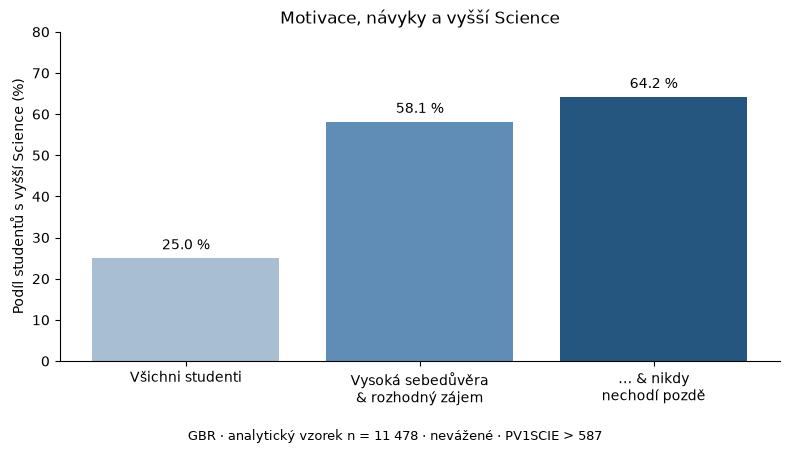

In [10]:
chart = pd.Series({
    "Všichni studenti": Q1_BASELINE,
    "Vysoká sebedůvěra\n& rozhodný zájem": q1_robustness.loc["jadro", "conf_PV1"],
    "… & nikdy\nnechodí pozdě": q1_robustness.loc["jadro_dochazka", "conf_PV1"],
}) * 100

fig, ax = plt.subplots(figsize=(8, 4.5))
bars = ax.bar(chart.index, chart.values, color=["#A8BED3", "#608DB5", "#245680"])
ax.bar_label(bars, fmt="%.1f %%", padding=4)
ax.set_ylabel("Podíl studentů s vyšší Science (%)")
ax.set_ylim(0, 80)
ax.set_title("Motivace, návyky a vyšší Science")
ax.spines[["top", "right"]].set_visible(False)
fig.text(0.5, 0.01, f"GBR · analytický vzorek n = {len(q1):,} · nevážené · PV1SCIE > {Q1_THRESHOLD:.0f}".replace(",", " "),
         ha="center", fontsize=9)
fig.tight_layout(rect=[0, 0.05, 1, 1])
fig.savefig(OUTPUT / "q1_graf.png", dpi=200, facecolor="white")
plt.show()

---
# Q2 – CF-Miner: čas a způsob učení ⇒ rozdělení Science

## Analytický vzorek a kategorizace

- `ukoly_celkem` (ST296Q04JA): čas na všechny domácí úkoly denně; „3–4 h“ a „víc než 4 h“ slučujeme (málo studentů).
- `uceni_navic` (ST071Q01NA): hodiny učení přírodních věd navíc týdně → 0 / 1–3 / 4–6 / 7+.
- `planovani` (ST432Q02DA): „Plánuji si, jak se budu učit“ – 4 úrovně frekvence.
- `vytrvalost` (PERSEV): stejná logika jako v Q1, ale hranice z vlastního vzorku Q2.
- **Cíl** `science_q`: kvartily PV1SCIE analytického vzorku (Q1 nejnižší … Q4 nejvyšší).
  Celkový histogram je rovnoměrný (25 % v každém kvartilu), takže rostoucí nebo klesající
  tvar ve skupině je přímo interpretovatelný.

In [11]:
q2 = df.loc[df[Q2_SOURCE + SCIENCE].notna().all(axis=1)].copy()
print("Analytický vzorek Q2:", len(q2), f"({100 * len(q2) / len(df):.1f} % GBR)")

q2_cat = pd.DataFrame(index=q2.index)
q2_cat["ukoly_celkem"] = ordered(q2["ST296Q04JA"], {
    1: "1_do_30min", 2: "2_30_60min", 3: "3_1_2h", 4: "4_2_3h", 5: "5_3h_a_vic", 6: "5_3h_a_vic",
})
q2_cat["uceni_navic"] = pd.cut(q2["ST071Q01NA"], [-0.5, 0.5, 3.5, 6.5, np.inf], labels=["0h", "1-3h", "4-6h", "7h+"])
q2_cat["planovani"] = ordered(q2["ST432Q02DA"], {1: "1_nikdy", 2: "2_nekdy", 3: "3_casto", 4: "4_velmi_casto"})
q2_cat["vytrvalost"], q2_persev = terciles_by_quartiles(q2["PERSEV"])

Q2_CUTS = q2["PV1SCIE"].quantile([0.25, 0.5, 0.75]).to_numpy()
Q2_BINS = [-np.inf, *Q2_CUTS, np.inf]
QUARTILES = ["Q1", "Q2", "Q3", "Q4"]
q2_cat["science_q"] = pd.cut(q2["PV1SCIE"], Q2_BINS, labels=QUARTILES)

if q2_cat.isna().any().any():
    raise ValueError("Po kategorizaci vznikly chybějící hodnoty.")

print("Hranice kvartilů PV1SCIE:", np.round(Q2_CUTS, 1))
print("Hranice vytrvalosti (PERSEV):", np.round(q2_persev, 3))
q2_counts = pd.concat(
    {name: q2_cat[name].value_counts(sort=False) for name in q2_cat.columns},
    names=["atribut", "kategorie"],
).rename("pocet").to_frame()
q2_counts["podil_pct"] = (100 * q2_counts["pocet"] / len(q2_cat)).round(1)
q2_counts.to_csv(OUTPUT / "q2_kategorie.csv")
q2_counts

Analytický vzorek Q2: 10705 (68.9 % GBR)
Hranice kvartilů PV1SCIE: [455.9 524.1 590.6]
Hranice vytrvalosti (PERSEV): [-0.603  0.38 ]


pocet  podil_pct
atribut      kategorie                      
ukoly_celkem 1_do_30min      2055       19.2
             2_30_60min      2973       27.8
             3_1_2h          3252       30.4
             4_2_3h          1579       14.8
             5_3h_a_vic       846        7.9
uceni_navic  0h              4362       40.7
             1-3h            3887       36.3
             4-6h            1714       16.0
             7h+              742        6.9
planovani    1_nikdy         1723       16.1
             2_nekdy         4448       41.6
             3_casto         3194       29.8
             4_velmi_casto   1340       12.5
vytrvalost   nizka           2691       25.1
             stredni         5876       54.9
             vysoka          2138       20.0
science_q    Q1              2677       25.0
             Q2              2676       25.0
             Q3              2676       25.0
             Q4              2676       25.0

## Zadání CF-Mineru

- **Podmínka:** konjunkce 1–3 atributů, každý jako `seq` (1–2 sousední kategorie).
- **Běh A – „posun nahoru“:** Base ≥ 200, S_Up ≥ 3 (histogram roste ve všech třech krocích Q1→Q4)
  a RelMax ≥ 0,40 (v nejčastějším kvartilu je aspoň 40 % skupiny, tj. 1,6× víc než 25 %).
- **Běh B – „posun dolů“:** Base ≥ 200, S_Down ≥ 3 a RelMax ≥ 0,42.

In [12]:
Q2_ATTRIBUTES = ["ukoly_celkem", "uceni_navic", "planovani", "vytrvalost"]
Q2_COND = {
    "attributes": [{"name": name, "type": "seq", "minlen": 1, "maxlen": 2} for name in Q2_ATTRIBUTES],
    "minlen": 1,
    "maxlen": 3,
    "type": "con",
}
Q2_UP = {"Base": 200, "S_Up": 3, "RelMax": 0.40}
Q2_DOWN = {"Base": 200, "S_Down": 3, "RelMax": 0.42}

clm_up = quiet_cleverminer(df=q2_cat.copy(), proc="CFMiner", target="science_q", cond=Q2_COND, quantifiers=Q2_UP)
clm_down = quiet_cleverminer(df=q2_cat.copy(), proc="CFMiner", target="science_q", cond=Q2_COND, quantifiers=Q2_DOWN)


def cf_table(clm):
    rows = []
    for rule in clm.result["rules"]:
        hist = np.array(rule["params"]["hist"])
        rows.append({
            "ID": rule["rule_id"], "base": rule["params"]["base"],
            **{q: f"{share:.1%}" for q, share in zip(QUARTILES, hist / hist.sum())},
            "podminka": rule["cedents_str"]["cond"],
        })
    return pd.DataFrame(rows).to_string(index=False)


save_text(captured(clm_up.print_summary), "q2_souhrn_nahoru")
save_text(cf_table(clm_up), "q2_seznam_nahoru", title="Q2 – CF-Miner, běh A: rozdělení Science posunuté nahoru (S_Up ≥ 3, RelMax ≥ 0,40)")
save_text(captured(clm_down.print_summary), "q2_souhrn_dolu")
save_text(cf_table(clm_down), "q2_seznam_dolu", title="Q2 – CF-Miner, běh B: rozdělení Science posunuté dolů (S_Down ≥ 3, RelMax ≥ 0,42)")

CleverMiner task processing summary:

Task type : CFMiner
Number of verifications : 1179
Number of rules : 18
Total time needed : 00h 00m 00s
Time of data preparation : 00h 00m 00s
Time of rule mining : 00h 00m 00s


 ID  base    Q1    Q2    Q3    Q4                                                                          podminka
  1   437 11.2% 20.6% 24.5% 43.7% ukoly_celkem(2_30_60min 3_1_2h) & planovani(1_nikdy 2_nekdy) & vytrvalost(vysoka)
  2   324 10.8% 22.8% 23.5% 42.9%         ukoly_celkem(2_30_60min 3_1_2h) & planovani(2_nekdy) & vytrvalost(vysoka)
  3   245 10.2% 21.6% 25.3% 42.9%            ukoly_celkem(3_1_2h) & planovani(1_nikdy 2_nekdy) & vytrvalost(vysoka)
  4   337 10.4% 21.1% 24.0% 44.5%     ukoly_celkem(3_1_2h 4_2_3h) & planovani(1_nikdy 2_nekdy) & vytrvalost(vysoka)
  5   262 10.3% 21.0% 24.0% 44.7%             ukoly_celkem(3_1_2h 4_2_3h) & planovani(2_nekdy) & vytrvalost(vysoka)
  6   252 13.5% 21.0% 25.0% 40.5%                ukoly_celkem(4_2_3h) & uceni_navic(1-3h 4-6h) & vytrvalost(vysoka)
  7   223 13.0% 20.6% 22.9% 43.5%            ukoly_celkem(4_2_3h) & planovani(2_nekdy 3_casto) & vytrvalost(vysoka)
  8   585 14.2% 20.3% 24.3% 41.2%            uceni_navic(0h 1-3h) & plan

 ID  base    Q1    Q2    Q3    Q4                                                                                   podminka
  1   206 44.2% 25.2% 17.0% 13.6%                            ukoly_celkem(1_do_30min) & uceni_navic(0h) & planovani(3_casto)
  2   264 45.8% 24.6% 15.9% 13.6%              ukoly_celkem(1_do_30min) & uceni_navic(0h) & planovani(3_casto 4_velmi_casto)
  3   268 47.4% 24.6% 15.7% 12.3%                      ukoly_celkem(1_do_30min) & uceni_navic(1-3h 4-6h) & vytrvalost(nizka)
  4   290 47.2% 25.5% 15.5% 11.7%                                               ukoly_celkem(1_do_30min) & uceni_navic(4-6h)
  5   257 48.6% 25.3% 15.2% 10.9%                   ukoly_celkem(1_do_30min) & uceni_navic(4-6h) & vytrvalost(nizka stredni)
  6   388 45.1% 23.2% 16.8% 14.9%                                           ukoly_celkem(1_do_30min) & uceni_navic(4-6h 7h+)
  7   254 48.4% 23.2% 15.7% 12.6%              ukoly_celkem(1_do_30min) & uceni_navic(4-6h 7h+) & planovani(1_nikdy 2_nekdy)


## Detail vybraných pravidel

- **Nahoru:** úkoly 30 min–2 h denně & plánuje nikdy/někdy & vysoká vytrvalost.
- **Dolů:** úkoly do 30 min denně & 4–6 h učení přírodních věd navíc týdně.

In [13]:
def cf_rule_id(clm, condition):
    matches = [rule["rule_id"] for rule in clm.result["rules"] if rule["cedents_str"]["cond"] == condition]
    if len(matches) != 1:
        raise ValueError(f"Pravidlo nenalezeno jednoznačně: {condition}")
    return matches[0]


Q2_SELECTED = {
    "nahoru": (clm_up, "ukoly_celkem(2_30_60min 3_1_2h) & planovani(1_nikdy 2_nekdy) & vytrvalost(vysoka)"),
    "dolu": (clm_down, "ukoly_celkem(1_do_30min) & uceni_navic(4-6h)"),
}
Q2_CONDITIONS = {
    "nahoru": {"ukoly_celkem": ["2_30_60min", "3_1_2h"], "planovani": ["1_nikdy", "2_nekdy"], "vytrvalost": ["vysoka"]},
    "dolu": {"ukoly_celkem": ["1_do_30min"], "uceni_navic": ["4-6h"]},
}

details = []
for name, (clm, condition) in Q2_SELECTED.items():
    rule = cf_rule_id(clm, condition)
    details.append(captured(clm.print_rule, rule))

    manual = q2_cat.loc[mask_for(q2_cat, Q2_CONDITIONS[name]), "science_q"].value_counts(sort=False).to_numpy()
    mined = np.array(clm.get_hist(rule))
    assert (manual == mined).all(), (name, manual, mined)
    print(f"{name}: histogram sedí s ručním výpočtem {manual.tolist()}")

save_text("\n".join(details), "q2_detail_pravidel", title="Q2 – detail vybraných pravidel")

nahoru: histogram sedí s ručním výpočtem [49, 90, 107, 191]
dolu: histogram sedí s ručním výpočtem [137, 74, 45, 34]


Rule id : 1

Base :   437  Relative base : 0.041  Steps UP (consecutive) :     3  Steps DOWN (consecutive) :     0  Steps UP (any) :     3  Steps DOWN (any) :     0  Histogram maximum :   191  Histogram minimum :    49  Histogram relative maximum : 0.437 Histogram relative minimum : 0.112 

Condition  : ukoly_celkem(2_30_60min 3_1_2h) & planovani(1_nikdy 2_nekdy) & vytrvalost(vysoka)

Categories in target variable  ['Q1', 'Q2', 'Q3', 'Q4']
Histogram                      [49, 90, 107, 191]




Rule id : 4

Base :   290  Relative base : 0.027  Steps UP (consecutive) :     0  Steps DOWN (consecutive) :     3  Steps UP (any) :     0  Steps DOWN (any) :     3  Histogram maximum :   137  Histogram minimum :    34  Histogram relative maximum : 0.472 Histogram relative minimum : 0.117 

Condition  : ukoly_celkem(1_do_30min) & uceni_navic(4-6h)

Categories in target variable  ['Q1', 'Q2', 'Q3', 'Q4']
Histogram                      [137, 74, 45, 34]


## Ověření robustnosti přes PV

Pro obě vybraná pravidla přepočítáme histogram pro PV1–PV10 se stejnými hranicemi kvartilů
(z PV1) a vážený podíl podle `W_FSTUWT`.

In [14]:
rows = []
weights = q2["W_FSTUWT"]
for name, conditions in Q2_CONDITIONS.items():
    mask = mask_for(q2_cat, conditions)
    for pv in SCIENCE:
        quartile = pd.cut(q2[pv], Q2_BINS, labels=QUARTILES)
        shares = quartile[mask].value_counts(normalize=True, sort=False)
        weighted = weights[mask].groupby(quartile[mask], observed=False).sum() / weights[mask].sum()
        rows.append({
            "pravidlo": name, "PV": pv, "skupina": int(mask.sum()),
            **{f"{q}_pct": 100 * shares[q] for q in QUARTILES},
            "Q1_vazene_pct": 100 * weighted["Q1"], "Q4_vazene_pct": 100 * weighted["Q4"],
            "monotonni": bool(np.all(np.diff(shares.to_numpy()) > 0) if name == "nahoru" else np.all(np.diff(shares.to_numpy()) < 0)),
        })

q2_detail = pd.DataFrame(rows)
q2_robustness = q2_detail.groupby("pravidlo", sort=False).agg(
    skupina=("skupina", "first"),
    Q1_pct_prumer=("Q1_pct", "mean"),
    Q4_pct_prumer=("Q4_pct", "mean"),
    Q4_pct_min=("Q4_pct", "min"),
    Q4_pct_max=("Q4_pct", "max"),
    Q1_pct_min=("Q1_pct", "min"),
    Q1_pct_max=("Q1_pct", "max"),
    Q1_vazene_prumer=("Q1_vazene_pct", "mean"),
    Q4_vazene_prumer=("Q4_vazene_pct", "mean"),
    PV_s_monotonnim_tvarem=("monotonni", "sum"),
)
q2_robustness.round(1).to_csv(OUTPUT / "q2_robustnost.csv")
q2_robustness.round(1)

,skupina,Q1_pct_prumer,Q4_pct_prumer,Q4_pct_min,Q4_pct_max,Q1_pct_min,Q1_pct_max,Q1_vazene_prumer,Q4_vazene_prumer,PV_s_monotonnim_tvarem
pravidlo,,,,,,,,,,
nahoru,437,12.0,41.6,39.1,43.7,10.1,13.7,13.4,42.3,10
dolu,290,50.2,11.8,9.0,13.8,46.9,52.4,43.9,14.2,8


## Graf pro prezentaci

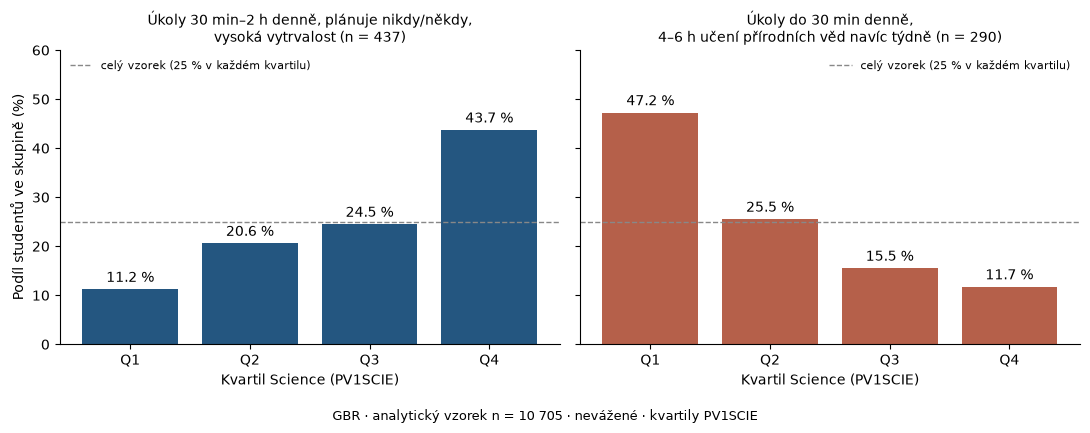

In [15]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.3), sharey=True)
titles = {
    "nahoru": "Úkoly 30 min–2 h denně, plánuje nikdy/někdy,\nvysoká vytrvalost",
    "dolu": "Úkoly do 30 min denně,\n4–6 h učení přírodních věd navíc týdně",
}
colors = {"nahoru": "#245680", "dolu": "#B5604A"}

for ax, name in zip(axes, ["nahoru", "dolu"]):
    shares = q2_cat.loc[mask_for(q2_cat, Q2_CONDITIONS[name]), "science_q"].value_counts(normalize=True, sort=False) * 100
    bars = ax.bar(QUARTILES, shares.values, color=colors[name])
    ax.axhline(25, color="#888888", linestyle="--", linewidth=1, label="celý vzorek (25 % v každém kvartilu)")
    ax.legend(loc="upper left" if name == "nahoru" else "upper right", frameon=False, fontsize=8)
    ax.bar_label(bars, fmt="%.1f %%", padding=3)
    ax.set_title(f"{titles[name]} (n = {int(mask_for(q2_cat, Q2_CONDITIONS[name]).sum())})", fontsize=10)
    ax.set_xlabel("Kvartil Science (PV1SCIE)")
    ax.spines[["top", "right"]].set_visible(False)

axes[0].set_ylabel("Podíl studentů ve skupině (%)")
axes[0].set_ylim(0, 60)
fig.text(0.5, 0.01, f"GBR · analytický vzorek n = {len(q2):,} · nevážené · kvartily PV1SCIE".replace(",", " "), ha="center", fontsize=9)
fig.tight_layout(rect=[0, 0.05, 1, 1])
fig.savefig(OUTPUT / "q2_graf.png", dpi=200, facecolor="white")
plt.show()

## Souhrn klíčových čísel

Ukládáme do `outputs/ondrej/souhrn.json` jako jediný zdroj čísel pro prezentaci.

In [16]:
summary = {
    "q1": {
        "vzorek": len(q1), "vzorek_pct_gbr": round(100 * len(q1) / len(df), 1),
        "hranice_science": round(Q1_THRESHOLD, 2), "baseline": round(Q1_BASELINE, 4),
        "kvantifikatory": Q1_QUANTIFIERS,
        "pravidel": len(clm_q1.result["rules"]),
        "vybrana": q1_robustness.round(4).reset_index().to_dict(orient="records"),
    },
    "q2": {
        "vzorek": len(q2), "vzorek_pct_gbr": round(100 * len(q2) / len(df), 1),
        "hranice_kvartilu": np.round(Q2_CUTS, 2).tolist(),
        "kvantifikatory_nahoru": Q2_UP, "kvantifikatory_dolu": Q2_DOWN,
        "pravidel_nahoru": len(clm_up.result["rules"]), "pravidel_dolu": len(clm_down.result["rules"]),
        "vybrana": q2_robustness.round(2).reset_index().to_dict(orient="records"),
    },
}
for key, clm in [("q1", clm_q1), ("q2_nahoru", clm_up), ("q2_dolu", clm_down)]:
    line = [l for l in captured(clm.print_summary).splitlines() if "Number of verifications" in l]
    summary.setdefault("verifikace", {})[key] = int(line[0].split(":")[1]) if line else None

(OUTPUT / "souhrn.json").write_text(json.dumps(summary, ensure_ascii=False, indent=2, default=float), encoding="utf-8")
print(json.dumps(summary, ensure_ascii=False, indent=2, default=float))

{
  "q1": {
    "vzorek": 11478,
    "vzorek_pct_gbr": 73.8,
    "hranice_science": 587.37,
    "baseline": 0.25,
    "kvantifikatory": {
      "Base": 200,
      "conf": 0.55
    },
    "pravidel": 28,
    "vybrana": [
      {
        "pravidlo": "jadro",
        "skupina": 908,
        "conf_PV1": 0.5815,
        "conf_prumer": 0.5805,
        "conf_min": 0.5628,
        "conf_max": 0.5903,
        "lift_prumer": 2.3175,
        "conf_vazena_prumer": 0.6035,
        "lift_vazeny_prumer": 2.0827,
        "PV_splnujicich_prahy": 10
      },
      {
        "pravidlo": "jadro_dochazka",
        "skupina": 581,
        "conf_PV1": 0.642,
        "conf_prumer": 0.6361,
        "conf_min": 0.6162,
        "conf_max": 0.6592,
        "lift_prumer": 2.5396,
        "conf_vazena_prumer": 0.6413,
        "lift_vazeny_prumer": 2.2129,
        "PV_splnujicich_prahy": 10
      }
    ]
  },
  "q2": {
    "vzorek": 10705,
    "vzorek_pct_gbr": 68.9,
    "hranice_kvartilu": [
      455.89,
      524

---
# Interpretace

> **Návrh vygenerovaný s pomocí AI – Ondřej musí projít, ověřit proti výstupům výše a přeformulovat vlastními slovy.**

### Q1 – motivace a návyky
- Ve vzorku GBR je vyšší Science (horní čtvrtina) nejsilněji spojena s kombinací **vysoké sebedůvěry
  v přírodních vědách a rozhodného zájmu o ně**: v této skupině má vyšší Science zhruba 58 % studentů
  oproti 25 % v celém vzorku (viz `q1_robustnost.csv`).
- Přidání **dochvilnosti** (nikdy nechodí pozdě) podíl dále zvyšuje přibližně na 64 %. Podobně
  se v nalezených pravidlech opakují „nevzdávám se snadno“ a očekávání vysokoškolského vzdělání.
- Všechna nalezená pravidla obsahují rozhodný zájem nebo vysokou sebedůvěru – samotné návyky
  bez motivace prahy nesplnily.
- Obě vybraná pravidla splňují prahy ve všech 10 PV; vážená confidence je 60,4 %, resp. 64,1 %.

### Q2 – čas a způsob učení
- Rozdělení Science posunuté **nahoru** mají skupiny s **vysokou vytrvalostí** (17 z 18 pravidel)
  a **středním objemem domácích úkolů** (30 min – 2 h denně): ve vybrané skupině je 43,7 % studentů
  v nejvyšším kvartilu (průměr přes 10 PV 41,6 %) oproti 25 % v celém vzorku.
- Plánování učení se v těchto pravidlech objevuje téměř jen jako „nikdy/někdy“ (časté plánování
  jen v 1 z 18 pravidel) – samo o sobě s lepšími výsledky ve vzorku nesouvisí.
- Posun **dolů** mají skupiny s **minimem domácích úkolů** (do 30 min denně), a to i když se
  přírodní vědy učí **4–6 h týdně navíc** – 47,2 % takových studentů je v nejnižším kvartilu
  (průměr přes 10 PV 50,2 %, vážený 43,9 %). Klesající tvar platí v 8 z 10 PV, je tedy o něco
  méně stabilní než rostoucí vzor (10 z 10 PV).
  Pravděpodobné vysvětlení je obrácená kauzalita: učení navíc (doučování) častěji dostávají slabší
  studenti; data to ale nedokazují.

### Omezení
- Souvislost ≠ příčinný vliv; zájem a sebedůvěra mohou být i důsledkem dobrých výsledků.
- Complete-case analýza (Q1 ~74 %, Q2 ~69 % GBR) může zkreslit složení vzorku.
- Kategorie indexů jsou relativní vůči vzorku, ne oficiální úrovně OECD.
- Ověření přes PV je kontrola citlivosti, ne ověření na nezávislých datech; nepoužili jsme
  replikační váhy ani standardní chyby.

# Deklarace použití AI

- **Nástroj:** Claude Code (Anthropic) – po potvrzení vyučujícího, že je AI v Bloku 1 povolena.
- **Co AI dělala:** prohledala codebook, navrhla kandidátní proměnné a explorační analýzu (notebook 04),
  navrhla analytické otázky a volbu procedur, napsala kód tohoto notebooku, doladila prahy kvantifikátorů
  a navrhla text interpretace.
- **Co dělal autor:** výběr oblasti a otázky z návrhů, kontrola kategorizace podle codebooku,
  revize a přepsání interpretace. *(doplnit, co konkrétně Ondřej upravil)*
- **Jak jsme výsledky ověřili:**
  čtyřpolní tabulky (Q1) a histogramy (Q2) z CleverMineru se shodují s ručním přepočtem v pandas (asserty výše);
  robustnost přes 10 PV a vážení `W_FSTUWT`; kontrola, že po kategorizaci nevznikly chybějící hodnoty;
  kontrola rozdělení kategorií proti codebooku; spuštění celého notebooku od začátku.